In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
print('Libraries ready:', pd.__version__, np.__version__, sklearn.__version__)

Libraries ready: 2.2.3 2.4.6 1.6.1


In [2]:
import os, requests, zipfile, io

# Download the public UCI Online Retail workbook
url = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
response = requests.get(url, timeout=60)
response.raise_for_status()
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    excel_name = next(name for name in archive.namelist() if name.lower().endswith('.xlsx'))
    with archive.open(excel_name) as file:
        raw = pd.read_excel(file)

print('Source file:', excel_name)
print('Raw shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print('Missing CustomerID:', raw['CustomerID'].isna().sum())
print('Duplicate rows:', raw.duplicated().sum())
raw.head()

Source file: Online Retail.xlsx
Raw shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Missing CustomerID: 135080
Duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Step 3: clean transaction-level records for customer analysis
rows_before = len(raw)
missing_customer = raw['CustomerID'].isna().sum()
duplicate_rows = raw.duplicated().sum()

clean = raw.dropna(subset=['CustomerID']).copy()
clean = clean.drop_duplicates()
clean['InvoiceNo'] = clean['InvoiceNo'].astype(str)
clean = clean[~clean['InvoiceNo'].str.startswith('C')]
clean = clean[(clean['Quantity'] > 0) & (clean['UnitPrice'] > 0)].copy()
clean['InvoiceDate'] = pd.to_datetime(clean['InvoiceDate'])
clean['CustomerID'] = clean['CustomerID'].astype('int64')
clean['Revenue'] = clean['Quantity'] * clean['UnitPrice']

print(f'Rows before cleaning: {rows_before:,}')
print(f'Missing CustomerID removed: {missing_customer:,}')
print(f'Duplicate rows removed: {duplicate_rows:,}')
print(f'Clean rows: {len(clean):,}')
print(f'Customers retained: {clean.CustomerID.nunique():,}')
print(f'Invoices retained: {clean.InvoiceNo.nunique():,}')
print(f'Cancelled, nonpositive quantity/price excluded; Revenue computed.')
print('Remaining missing values:', int(clean.isna().sum().sum()))
clean.head()

Rows before cleaning: 541,909
Missing CustomerID removed: 135,080
Duplicate rows removed: 5,268
Clean rows: 392,692
Customers retained: 4,338
Invoices retained: 18,532
Cancelled, nonpositive quantity/price excluded; Revenue computed.
Remaining missing values: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Analysis period: 2010-12-01 to 2011-12-09
Customers: 4338
Total spend (currency units):
count      4338.00
mean       2048.69
std        8985.23
min           3.75
25%         306.48
50%         668.57
75%        1660.60
90%        3640.84
99%       19780.49
max      280206.02
Name: TotalSpend, dtype: float64
Distinct orders per customer:
count    4338.00
mean        4.27
std         7.70
min         1.00
25%         1.00
50%         2.00
75%         5.00
90%         9.00
max       209.00
Name: OrderCount, dtype: float64
Days since last purchase:
count    4338.00
mean       92.54
std       100.01
min         1.00
25%        18.00
50%        51.00
75%       142.00
90%       263.00
max       374.00
Name: DaysSinceLastPurchase, dtype: float64
Customers with one order: 34.4%


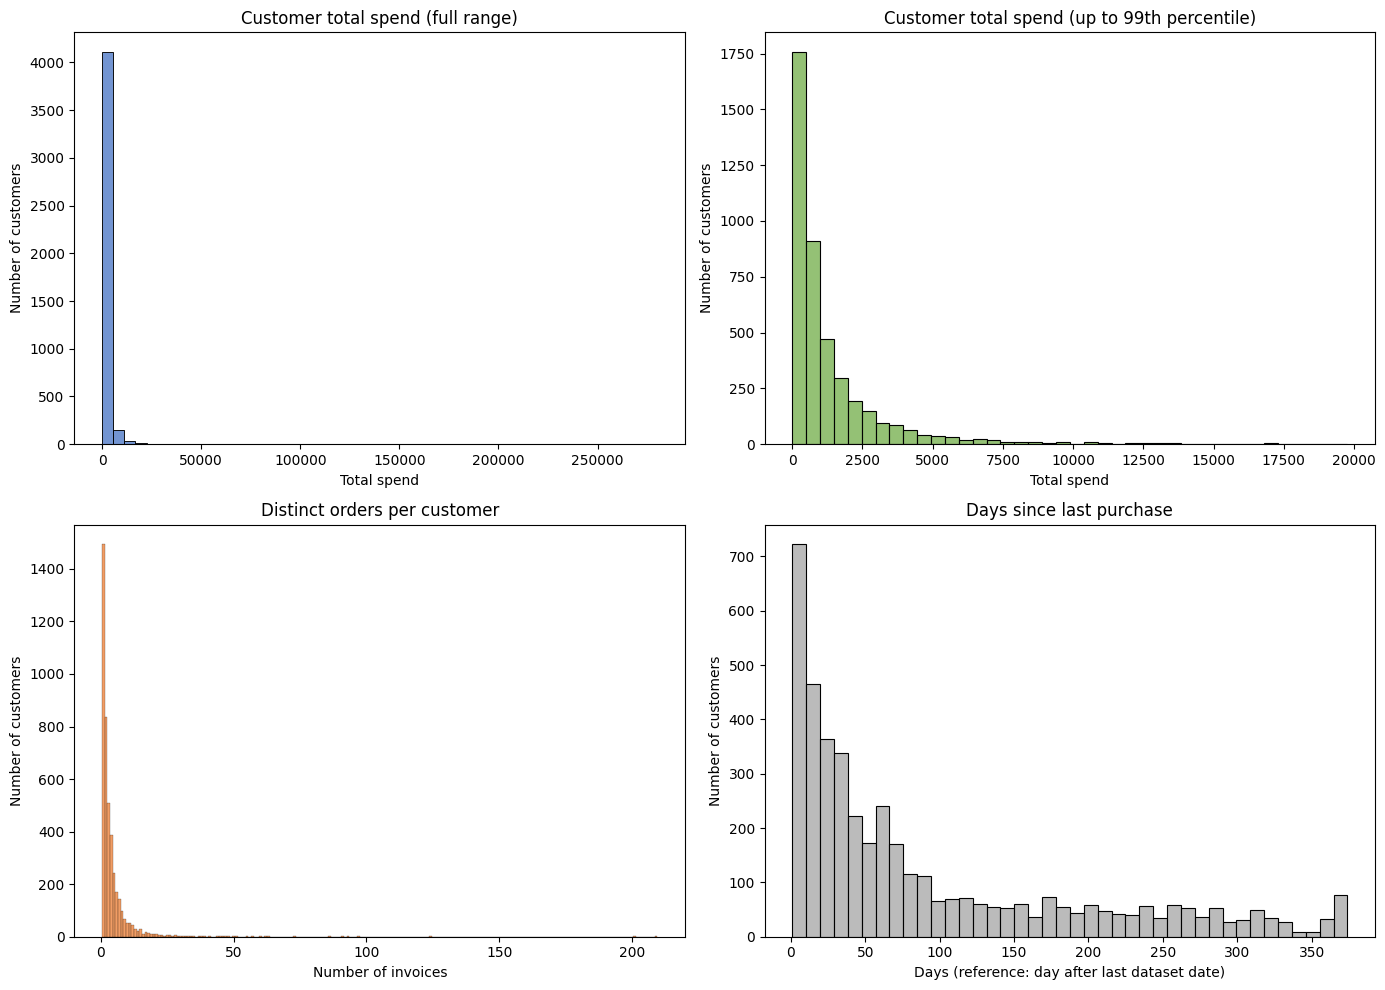

In [4]:
# Step 4: Exploratory Data Analysis (EDA)
# Summarize each customer's spend, purchase frequency, and recency.
analysis_date = clean['InvoiceDate'].max() + pd.Timedelta(days=1)
customer_eda = clean.groupby('CustomerID').agg(
    TotalSpend=('Revenue', 'sum'),
    OrderCount=('InvoiceNo', 'nunique'),
    LastPurchase=('InvoiceDate', 'max'),
    UnitsPurchased=('Quantity', 'sum')
)
customer_eda['DaysSinceLastPurchase'] = (analysis_date - customer_eda['LastPurchase']).dt.days

print('Analysis period:', clean['InvoiceDate'].min().date(), 'to', clean['InvoiceDate'].max().date())
print('Customers:', len(customer_eda))
print('Total spend (currency units):')
print(customer_eda['TotalSpend'].describe(percentiles=[.25, .5, .75, .90, .99]).round(2))
print('Distinct orders per customer:')
print(customer_eda['OrderCount'].describe(percentiles=[.25, .5, .75, .90]).round(2))
print('Days since last purchase:')
print(customer_eda['DaysSinceLastPurchase'].describe(percentiles=[.25, .5, .75, .90]).round(2))
print(f"Customers with one order: {(customer_eda['OrderCount'].eq(1).mean() * 100):.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(customer_eda['TotalSpend'], bins=50, ax=axes[0, 0], color='#4472C4')
axes[0, 0].set(title='Customer total spend (full range)', xlabel='Total spend', ylabel='Number of customers')
spend_cap = customer_eda['TotalSpend'].quantile(.99)
sns.histplot(customer_eda.loc[customer_eda['TotalSpend'] <= spend_cap, 'TotalSpend'], bins=40, ax=axes[0, 1], color='#70AD47')
axes[0, 1].set(title='Customer total spend (up to 99th percentile)', xlabel='Total spend', ylabel='Number of customers')
sns.histplot(customer_eda['OrderCount'], discrete=True, ax=axes[1, 0], color='#ED7D31')
axes[1, 0].set(title='Distinct orders per customer', xlabel='Number of invoices', ylabel='Number of customers')
sns.histplot(customer_eda['DaysSinceLastPurchase'], bins=40, ax=axes[1, 1], color='#A5A5A5')
axes[1, 1].set(title='Days since last purchase', xlabel='Days (reference: day after last dataset date)', ylabel='Number of customers')
plt.tight_layout()
plt.show()

In [5]:
# Step 5: RFM Analysis
# Recency uses the day after the latest transaction as the reference date.
rfm = clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda dates: (analysis_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

# Keep one row per customer and verify the required RFM fields.
assert rfm['CustomerID'].is_unique
assert rfm[['Recency', 'Frequency', 'Monetary']].notna().all().all()
print('RFM reference date:', analysis_date.date())
print('Customer rows:', len(rfm))
print('Unique customers:', rfm['CustomerID'].nunique())
print('Columns:', rfm.columns.tolist())
print('Duplicate customer IDs:', rfm['CustomerID'].duplicated().sum())
rfm.head(10)

RFM reference date: 2011-12-10
Customer rows: 4338
Unique customers: 4338
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary']
Duplicate customer IDs: 0


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


RFM features were log1p transformed and standardized.
 K  Inertia  Silhouette
 2 6483.589       0.433
 3 4869.489       0.337
 4 3938.603       0.337
 5 3296.709       0.316
 6 2855.526       0.313
 7 2548.820       0.309
 8 2336.341       0.303


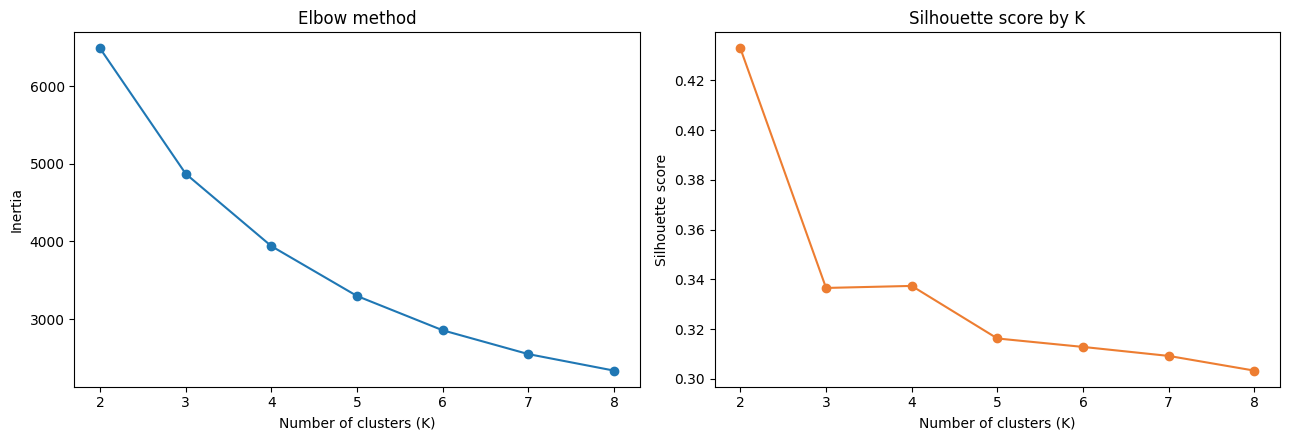

Selected K (highest tested silhouette): 2
Cluster RFM profiles (count, median, mean):


Recency                Frequency              Monetary           \
          count median    mean     count median  mean    count   median   
Cluster                                                                   
0          2672   96.0  134.09      2672    1.0  1.67     2672   363.08   
1          1666   16.0   25.89      1666    6.0  8.44     1666  2061.08   

                  
            mean  
Cluster           
0         495.59  
1        4539.60

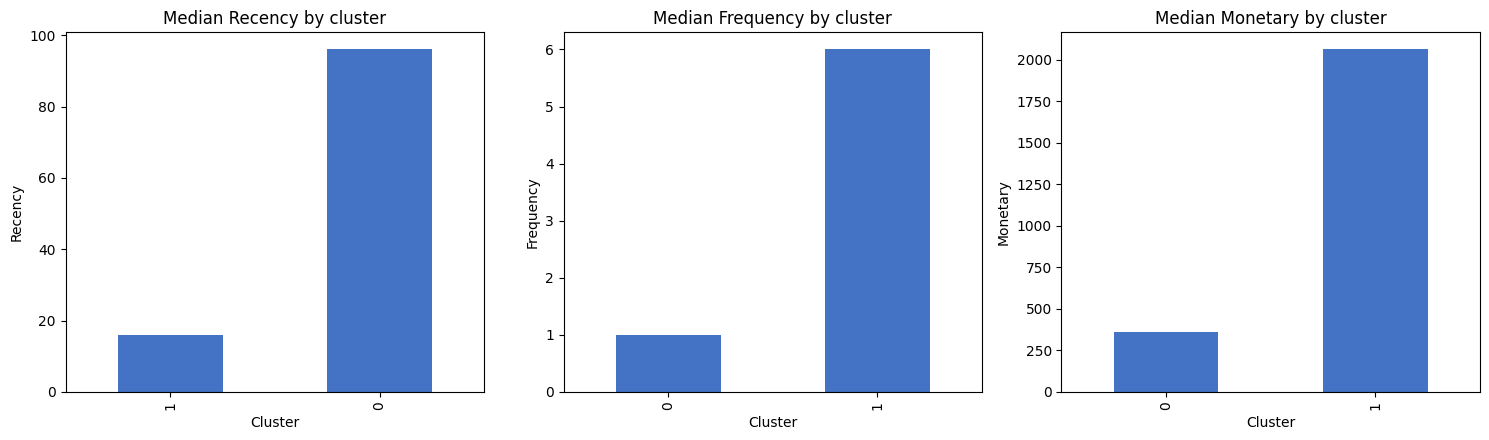

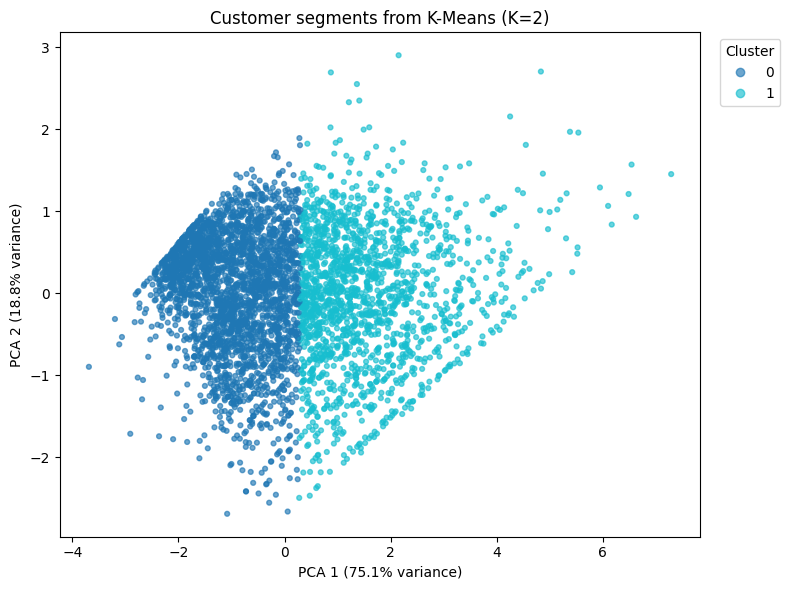

Cluster sizes:
Cluster
0    2672
1    1666


In [6]:
# Step 6: prepare RFM, compare K values, and fit K-Means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# R, F, and M are strongly right-skewed, so log1p reduces the influence of extreme values.
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()
rfm_log = np.log1p(rfm_features)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

k_values = range(2, 9)
model_results = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(rfm_scaled)
    model_results.append({
        'K': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(rfm_scaled, labels)
    })
metrics = pd.DataFrame(model_results)
print('RFM features were log1p transformed and standardized.')
print(metrics.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(metrics['K'], metrics['Inertia'], marker='o')
axes[0].set(title='Elbow method', xlabel='Number of clusters (K)', ylabel='Inertia')
axes[1].plot(metrics['K'], metrics['Silhouette'], marker='o', color='#ED7D31')
axes[1].set(title='Silhouette score by K', xlabel='Number of clusters (K)', ylabel='Silhouette score')
plt.tight_layout()
plt.show()

# Use the best silhouette among the tested K values as a reproducible starting choice.
best_k = int(metrics.loc[metrics['Silhouette'].idxmax(), 'K'])
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
rfm['Cluster'] = final_kmeans.fit_predict(rfm_scaled)
print('Selected K (highest tested silhouette):', best_k)
cluster_profile = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].agg(['count', 'median', 'mean']).round(2)
print('Cluster RFM profiles (count, median, mean):')
display(cluster_profile)

# Compare clusters on original RFM scales using medians.
cluster_medians = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].median()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    cluster_medians[col].sort_values().plot(kind='bar', ax=ax, color='#4472C4')
    ax.set(title=f'Median {col} by cluster', xlabel='Cluster', ylabel=col)
plt.tight_layout()
plt.show()

# PCA provides a two-dimensional view of the three standardized RFM features.
pca = PCA(n_components=2, random_state=42)
rfm_2d = pca.fit_transform(rfm_scaled)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(rfm_2d[:, 0], rfm_2d[:, 1], c=rfm['Cluster'], cmap='tab10', s=12, alpha=0.65)
plt.title(f'Customer segments from K-Means (K={best_k})')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.legend(*scatter.legend_elements(), title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

cluster_sizes = rfm['Cluster'].value_counts().sort_index()
print('Cluster sizes:')
print(cluster_sizes.to_string())

# Step 7. Business Insights & Recommendations

## What the two groups look like

The model groups the 4,338 identified customers into two broad segments. Recency is measured from December 10, 2011, the day after the last transaction in the dataset. Among the tested options (K = 2 to 8), the two-cluster solution had the highest silhouette score (0.433). That makes it a useful starting point for interpretation, not proof that two groups are the only or best business answer.

- **Cluster 0 — Customers to reconnect with:** 2,672 customers (61.6%). Their median was 96 days since the last purchase, one distinct invoice, and 363.08 in total spend over the observation period. In this dataset, many bought once and had been inactive longer by the end of the period.
- **Cluster 1 — Recent, higher-value customers:** 1,666 customers (38.4%). Their median was 16 days since the last purchase, six invoices, and 2,061.08 in total spend. They were buying more recently and repeatedly, and their median spend was about 5.68 times that of Cluster 0.

These are useful patterns for deciding where to test different customer experiences. They are not permanent labels: a customer can move between groups as their behavior changes. The spend figures are historical revenue totals in the dataset’s currency units, not profit or predicted lifetime value.

## What a retailer could try next

### For Cluster 1: make repeat buying feel worthwhile

- **Recognize the relationship:** offer early access to seasonal launches, a simple loyalty perk, or useful service benefits. Keep the reward tied to engagement instead of automatically discounting every purchase.
- **Make recommendations relevant:** use each customer’s past product categories to suggest complementary items or replenishment options. Start with a small number of clear, useful suggestions rather than sending a broad catalogue.
- **Build on what is already working:** test curated bundles or product pairings that increase convenience and basket size. Track repeat purchase rate and average order value alongside margin, so a higher basket does not hide an unprofitable discount.
- **Protect the experience:** set a sensible contact frequency and suppress messages after a purchase when they would be irrelevant. Monitor opt-outs, complaints, and returns as well as sales.

### For Cluster 0: earn a reason to come back

- **Start with a helpful reminder:** show a small selection related to the customer’s previous purchases, refreshed with current stock or seasonal items. Make the message easy to ignore and avoid implying that the customer has a particular motivation.
- **Test a modest incentive:** compare a no-discount reminder with a limited, low-cost offer. Use minimum-spend thresholds or category-specific offers only when the expected margin supports them.
- **Reduce friction:** highlight straightforward delivery, returns, or product information if those are relevant customer benefits. The transaction data alone cannot tell us which barrier, if any, prevented another purchase.
- **Set a stopping rule:** if a customer does not respond after a small number of well-spaced attempts, pause outreach rather than escalating discounts indefinitely.

### For both groups: run a fair test

Randomly assign eligible customers within each segment to a campaign and a holdout group. Compare incremental repeat purchases, revenue and gross margin per customer, offer cost, and opt-outs over a pre-defined period. This helps distinguish campaign impact from purchases that would have happened anyway. Review the results before expanding the campaign.

## How to read these results

This is an exploratory analysis of UCI Online Retail transactions from December 2010 through December 9, 2011. It includes only customers with an identifiable CustomerID and excludes cancellations, non-positive quantities or prices, and duplicate rows during cleaning. The dataset is historical and may not reflect a retailer’s current customers, products, channels, or market.

RFM summarizes observed transactions; it does not reveal why someone bought, their demographics, satisfaction, or ability to respond to an offer. K-Means assigns customers based on the selected features and modeling choices. A cluster is not a natural customer identity, and neither the segments nor the recommendations establish cause and effect. The analysis also does not measure profit, campaign costs, or customer lifetime value. A retailer should validate the segments on current data and use controlled experiments to learn whether a proposed action creates profitable incremental behavior.

In [7]:
# Step 8: package the analysis, figures, README, and report in Google Drive
from google.colab import drive
from pathlib import Path
import shutil, textwrap
from matplotlib.backends.backend_pdf import PdfPages

drive.mount('/content/drive')
project_dir = Path('/content/drive/MyDrive/customer-segmentation')
fig_dir = project_dir / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)

# Save four figures used to explain the analysis.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(customer_eda['TotalSpend'], bins=50, ax=axes[0, 0], color='#4472C4')
axes[0, 0].set(title='Customer spend (full range)', xlabel='Total spend', ylabel='Customers')
cap = customer_eda['TotalSpend'].quantile(.99)
sns.histplot(customer_eda.loc[customer_eda['TotalSpend'] <= cap, 'TotalSpend'], bins=40, ax=axes[0, 1], color='#70AD47')
axes[0, 1].set(title='Customer spend (up to 99th percentile)', xlabel='Total spend', ylabel='Customers')
sns.histplot(customer_eda['OrderCount'], discrete=True, ax=axes[1, 0], color='#ED7D31')
axes[1, 0].set(title='Distinct orders per customer', xlabel='Invoices', ylabel='Customers')
sns.histplot(customer_eda['DaysSinceLastPurchase'], bins=40, ax=axes[1, 1], color='#A5A5A5')
axes[1, 1].set(title='Days since last purchase', xlabel='Days', ylabel='Customers')
fig.tight_layout(); fig.savefig(fig_dir / 'eda_distributions.png', dpi=180, bbox_inches='tight'); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(metrics['K'], metrics['Inertia'], marker='o', color='#4472C4')
axes[0].set(title='Elbow method', xlabel='Number of clusters (K)', ylabel='Inertia')
axes[1].plot(metrics['K'], metrics['Silhouette'], marker='o', color='#ED7D31')
axes[1].set(title='Silhouette score by K', xlabel='Number of clusters (K)', ylabel='Silhouette score')
fig.tight_layout(); fig.savefig(fig_dir / 'cluster_evaluation.png', dpi=180, bbox_inches='tight'); plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    cluster_medians[col].sort_index().plot(kind='bar', ax=ax, color='#4472C4')
    ax.set(title=f'Median {col} by cluster', xlabel='Cluster', ylabel=col)
fig.tight_layout(); fig.savefig(fig_dir / 'cluster_profiles.png', dpi=180, bbox_inches='tight'); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(rfm_2d[:, 0], rfm_2d[:, 1], c=rfm['Cluster'], cmap='tab10', s=12, alpha=.65)
ax.set(title=f'Customer segments from K-Means (K={best_k})', xlabel='PCA 1', ylabel='PCA 2')
ax.legend(*scatter.legend_elements(), title='Cluster')
fig.tight_layout(); fig.savefig(fig_dir / 'customer_segments_pca.png', dpi=180, bbox_inches='tight'); plt.close(fig)

rfm.to_csv(project_dir / 'customer_rfm_segments.csv', index=False)
readme = '''# Customer Segmentation Using Transactional Data

## Project question
How can a retailer use observed purchasing behavior to identify practical customer groups and design testable marketing actions?

## Project contents
- analysis.ipynb: complete Google Colab analysis notebook.
- customer_rfm_segments.csv: one row per identified customer, with RFM features and cluster assignment.
- figures/: exploratory and clustering charts.
- business_insights.pdf: concise business interpretation and recommendations.

## Data and methods
The project uses the public UCI Online Retail transaction dataset (December 2010–December 9, 2011). Cleaning removes rows without CustomerID, duplicate rows, cancellations, and non-positive quantities or unit prices. Transaction revenue is Quantity × UnitPrice. Customer-level Recency, Frequency, and Monetary (RFM) features are calculated, log-transformed with log1p, standardized, and clustered with K-Means. K values from 2 through 8 are compared using inertia and silhouette score.

The two-cluster solution had the highest silhouette score among the tested values (0.433). It is an exploratory starting point, not a definitive or causal classification.

## Main findings
- Cluster 0 contains 2,672 customers (61.6%); median Recency is 96 days, Frequency is 1 invoice, and Monetary is 363.08.
- Cluster 1 contains 1,666 customers (38.4%); median Recency is 16 days, Frequency is 6 invoices, and Monetary is 2,061.08.
- Cluster 1's median observed spend is about 5.68 times Cluster 0's. Monetary is historical revenue in the dataset's currency units, not profit or lifetime value.

## Suggested next step
Test retention and win-back ideas with randomized holdout groups. Measure incremental repeat purchases, revenue, gross margin, offer cost, and opt-outs before scaling.

## Limitations
The data are historical and include only customers with an identifiable CustomerID. RFM reflects recorded transactions, not motivation, demographics, satisfaction, or response propensity. K-Means segments depend on feature and modeling choices and do not establish cause and effect. Profit, campaign costs, and customer lifetime value are not measured.

## Reproducibility
Open analysis.ipynb in Google Colab and run the cells from top to bottom. The source dataset is public at https://archive.ics.uci.edu/dataset/352/online+retail.
'''
(project_dir / 'README.md').write_text(readme, encoding='utf-8')

def add_text_page(pdf, title, paragraphs):
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(.08, .95, title, fontsize=20, weight='bold', va='top')
    y = .89
    for paragraph in paragraphs:
        wrapped = textwrap.fill(paragraph, width=92)
        fig.text(.08, y, wrapped, fontsize=11, va='top', linespacing=1.45)
        y -= .035 * (wrapped.count('\n') + 1) + .025
    pdf.savefig(fig, bbox_inches='tight'); plt.close(fig)

with PdfPages(project_dir / 'business_insights.pdf') as pdf:
    add_text_page(pdf, 'Customer Segmentation: Business Insights', [
        'Project question: How can observed purchasing behavior help a retailer identify useful customer groups and design testable marketing actions?',
        'Dataset and scope: UCI Online Retail transactions from December 2010 through December 9, 2011. The cleaned analysis contains 392,692 transaction rows from 4,338 customers with an identifiable CustomerID. Cancellations, duplicate rows, and non-positive quantities or prices were excluded.',
        'Approach: Customer Recency, Frequency, and Monetary (RFM) features were calculated. After log1p transformation and standardization, K-Means solutions for K = 2 through 8 were compared using inertia and silhouette score. K = 2 had the highest tested silhouette score (0.433), so it is an exploratory starting point.',
        'At a glance: Cluster 0 includes 2,672 customers (61.6%); Cluster 1 includes 1,666 customers (38.4%). Cluster 1 has a median observed spend of 2,061.08, about 5.68 times Cluster 0’s 363.08. These are historical revenue totals in the dataset currency units, not profit or lifetime value.'
    ])
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(.08, .95, 'Customer groups and evidence', fontsize=20, weight='bold', va='top')
    for y, filename, height in [(.67, 'cluster_profiles.png', .23), (.34, 'customer_segments_pca.png', .28), (.08, 'cluster_evaluation.png', .22)]:
        img = plt.imread(fig_dir / filename)
        ax = fig.add_axes([.12, y, .76, height]); ax.imshow(img); ax.axis('off')
    pdf.savefig(fig, bbox_inches='tight'); plt.close(fig)
    add_text_page(pdf, 'Recommendations and limitations', [
        'For Cluster 1 — retain and deepen engagement: offer relevant early access or a modest loyalty benefit; recommend complementary products based on past categories; test curated bundles; and manage contact frequency. Track repeat purchase, average order value, gross margin, opt-outs, and returns.',
        'For Cluster 0 — invite a return: begin with a helpful, category-relevant reminder; compare it with a modest, time-limited incentive; reduce purchase friction with clear product and delivery information; and set a stopping rule for non-responders. Avoid escalating discounts without evidence of profitable incremental purchases.',
        'For both groups — test before scaling: randomly assign eligible customers within each segment to campaign and holdout groups. Compare incremental repeat purchases, revenue and gross margin per customer, offer cost, and opt-outs over a pre-defined period.',
        'Limitations: the dataset is historical and excludes customers without an identifiable CustomerID. RFM describes recorded purchases, not customer motivation, demographics, satisfaction, or offer responsiveness. K-Means labels depend on chosen features and settings; clusters are not natural identities and do not establish causality. Profit, campaign costs, and lifetime value are not measured. Revalidate on current data and run controlled experiments before operational use.'
    ])

# Copy the saved Colab notebook into the deliverable folder when available.
notebook_candidates = [Path('/content/drive/MyDrive/Colab Notebooks/Customer_Segmentation.ipynb'), Path('/content/drive/MyDrive/Customer_Segmentation.ipynb')]
notebook_source = next((p for p in notebook_candidates if p.exists()), None)
if notebook_source:
    shutil.copy2(notebook_source, project_dir / 'analysis.ipynb')
else:
    print('Notebook remains saved in Google Drive as Customer_Segmentation.ipynb; copy it into this folder from Drive if needed.')

print('Project folder:', project_dir)
print('Files:', sorted(str(p.relative_to(project_dir)) for p in project_dir.rglob('*') if p.is_file()))
print('Report pages: 3')

Mounted at /content/drive
Project folder: /content/drive/MyDrive/customer-segmentation
Files: ['README.md', 'analysis.ipynb', 'business_insights.pdf', 'customer_rfm_segments.csv', 'figures/cluster_evaluation.png', 'figures/cluster_profiles.png', 'figures/customer_segments_pca.png', 'figures/eda_distributions.png']
Report pages: 3
